**Kaggle CLI:**

pip install kaggle

base: kaggle datasets download -d owner/ten-dataset

**Dataset 8:**

kaggle datasets download -d rohiteng/amazon-sales-dataset


kaggle datasets download -d rohiteng/amazon-sales-dataset --unzip


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df_goc = pd.read_csv('../data/raw/Amazon_raw.csv', low_memory=False)
df_goc.head()

,OrderID,OrderDate,CustomerID,CustomerName,ProductID,ProductName,Category,Brand,Quantity,UnitPrice,Discount,Tax,ShippingCost,TotalAmount,PaymentMethod,OrderStatus,City,State,Country,SellerID
0,ORD0000001,2023-01-31,CUST001504,Vihaan Sharma,P00014,Drone Mini,Books,BrightLux,3,106.59,0.00,0.00,0.09,319.86,Debit Card,Delivered,Washington,DC,India,SELL01967
1,ORD0000002,2023-12-30,CUST000178,Pooja Kumar,P00040,Microphone,Home & Kitchen,UrbanStyle,1,251.37,0.05,19.10,1.74,259.64,Amazon Pay,Delivered,Fort Worth,TX,United States,SELL01298
2,ORD0000003,2022-05-10,CUST047516,Sneha Singh,P00044,Power Bank 20000mAh,Clothing,UrbanStyle,3,35.03,0.10,7.57,5.91,108.06,Debit Card,Delivered,Austin,TX,United States,SELL00908
3,ORD0000004,2023-07-18,CUST030059,Vihaan Reddy,P00041,Webcam Full HD,Home & Kitchen,Zenith,5,33.58,0.15,11.42,5.53,159.66,Cash on Delivery,Delivered,Charlotte,NC,India,SELL01164
4,ORD0000005,2023-02-04,CUST048677,Aditya Kapoor,P00029,T-Shirt,Clothing,KiddoFun,2,515.64,0.25,38.67,9.23,821.36,Credit Card,Cancelled,San Antonio,TX,Canada,SELL01411


In [3]:
df_goc.tail()

,OrderID,OrderDate,CustomerID,CustomerName,ProductID,ProductName,Category,Brand,Quantity,UnitPrice,Discount,Tax,ShippingCost,TotalAmount,PaymentMethod,OrderStatus,City,State,Country,SellerID
99995,ORD0099996,2023-03-07,CUST001356,Karan Joshi,P00047,Memory Card 128GB,Electronics,Apex,2,492.34,0.00,78.77,2.75,1066.20,UPI,Delivered,Jacksonville,FL,India,SELL00041
99996,ORD0099997,2021-11-24,CUST031254,Sunita Kapoor,P00046,Car Charger,Sports & Outdoors,Apex,5,449.30,0.00,179.72,6.07,2432.29,Credit Card,Delivered,San Jose,CA,United States,SELL01449
99997,ORD0099998,2023-04-29,CUST012579,Aman Gupta,P00030,Dress Shirt,Sports & Outdoors,BrightLux,4,232.40,0.00,74.37,12.43,1016.40,Cash on Delivery,Delivered,Indianapolis,IN,United States,SELL00028
99998,ORD0099999,2021-11-01,CUST026243,Simran Gupta,P00046,Car Charger,Sports & Outdoors,HomeEase,1,294.05,0.00,23.52,13.09,330.66,Debit Card,Delivered,Charlotte,NC,United States,SELL00324
99999,ORD0100000,2021-12-04,CUST029492,Sunita Reddy,P00019,LED Desk Lamp,Home & Kitchen,CoreTech,5,166.70,0.05,63.35,3.34,858.52,Debit Card,Delivered,New York,NY,United States,SELL00761


In [4]:
#dataset có bao nhiêu mục, cột dòng
print(df_goc.shape)

(100000, 20)


In [5]:
#hàm mô tả bước làm sạch dữ liệu
def ghi(buoc, mo_ta, so_dong):
    nhat_ky.append({"buoc": buoc, "mo_ta": mo_ta, "so_dong_con_lai": so_dong})
    print(f"[{buoc}] {mo_ta} -> dữ liệu sạch: {so_dong} dòng")

In [6]:
#BẮT ĐẦU LÀM SẠCH
df = df_goc.copy()
nhat_ky = []

ghi("0. Ban đầu", "Đọc file gốc", len(df))
print()
df.info()

[0. Ban đầu] Đọc file gốc -> dữ liệu sạch: 100000 dòng

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   OrderID        100000 non-null  str    
 1   OrderDate      100000 non-null  str    
 2   CustomerID     100000 non-null  str    
 3   CustomerName   100000 non-null  str    
 4   ProductID      100000 non-null  str    
 5   ProductName    100000 non-null  str    
 6   Category       100000 non-null  str    
 7   Brand          100000 non-null  str    
 8   Quantity       100000 non-null  int64  
 9   UnitPrice      100000 non-null  float64
 10  Discount       100000 non-null  float64
 11  Tax            100000 non-null  float64
 12  ShippingCost   100000 non-null  float64
 13  TotalAmount    100000 non-null  float64
 14  PaymentMethod  100000 non-null  str    
 15  OrderStatus    100000 non-null  str    
 16  City           100000 non-null

In [7]:
#1. LÀM SẠCH GIÁ TRỊ THIẾU
# 1a. Thiếu null
print(df.isnull().sum().sum(), "ô NaN")

# 1b. Thiếu ngụy trang
cot_chu = df.select_dtypes(include=["object", "string"]).columns
nghi_van = ["", "n/a", "na", "null", "none", "unknown", "-", "?", "nan"]
print(f'Có tổng {len(cot_chu)} các cột sau:')
print(list(cot_chu))

for c in cot_chu:
    so_loi = df[c].str.strip().str.lower().isin(nghi_van).sum()
    if so_loi > 0:
        print(f"{c}: {so_loi} giá trị nghi là thiếu")

# 1c. Giá trị đếm được ở các cột phân loại, để mắt thường phát hiện bất thường
for c in ["Category", "PaymentMethod", "OrderStatus", "Country"]:
    print("\n", df[c].value_counts())

print()
ghi("1. Giá trị thiếu", "Kiểm tra giá trị NaN và ngụy trang: không phát hiện", len(df))

0 ô NaN
Có tổng 14 các cột sau:
['OrderID', 'OrderDate', 'CustomerID', 'CustomerName', 'ProductID', 'ProductName', 'Category', 'Brand', 'PaymentMethod', 'OrderStatus', 'City', 'State', 'Country', 'SellerID']

 Category
Electronics          16853
Sports & Outdoors    16804
Books                16752
Home & Kitchen       16610
Toys & Games         16542
Clothing             16439
Name: count, dtype: int64

 PaymentMethod
Credit Card         35038
Debit Card          20024
UPI                 15066
Amazon Pay          15017
Net Banking          9927
Cash on Delivery     4928
Name: count, dtype: int64

 OrderStatus
Delivered    74628
Shipped      15192
Pending       4103
Returned      3049
Cancelled     3028
Name: count, dtype: int64

 Country
United States     70058
India             15051
Canada             5818
United Kingdom     4943
Australia          4130
Name: count, dtype: int64

[1. Giá trị thiếu] Kiểm tra giá trị NaN và ngụy trang: không phát hiện -> dữ liệu sạch: 100000 dòng


In [8]:
#2. LÀM SẠCH GIÁ TRỊ DÒNG TRÙNG
print("Trùng toàn bộ dòng:", df.duplicated().sum())
print("Trùng OrderID:", df["OrderID"].duplicated().sum())

truoc = len(df)
df = df.drop_duplicates()

print()
ghi("2. Trùng lặp", f"Xóa {truoc - len(df)} dòng trùng hoàn toàn", len(df))

Trùng toàn bộ dòng: 0
Trùng OrderID: 0

[2. Trùng lặp] Xóa 0 dòng trùng hoàn toàn -> dữ liệu sạch: 100000 dòng


In [9]:
#3. LÀM SẠCH GIÁ TRỊ NGÀY
print(df["OrderDate"].sample(10, random_state=1).tolist())   # xem định dạng thực tế - 10 dòng

['2021-06-30', '2024-04-30', '2024-03-02', '2022-07-18', '2021-11-08', '2022-02-16', '2022-09-01', '2023-07-02', '2023-08-29', '2020-02-11']


In [10]:
ngay = pd.to_datetime(df["OrderDate"], errors="coerce")
print("Không đọc được:", ngay.isnull().sum())

df["OrderDate"] = ngay
print("Từ", df["OrderDate"].min(), "đến", df["OrderDate"].max())

truoc = len(df)
df = df.dropna(subset=["OrderDate"])

print()
ghi("3. Định dạng ngày", f"Ép datetime, bỏ {truoc - len(df)} dòng ngày lỗi", len(df))

Không đọc được: 0
Từ 2020-01-01 00:00:00 đến 2024-12-29 00:00:00

[3. Định dạng ngày] Ép datetime, bỏ 0 dòng ngày lỗi -> dữ liệu sạch: 100000 dòng


In [ ]:
#4. LÀM SẠCH GIÁ TRỊ SỐ HỌC VÔ LÝ

kiem_tra = {
    "Quantity <= 0":        df["Quantity"] <= 0,
    "UnitPrice <= 0":       df["UnitPrice"] <= 0,
    "Discount ngoài [0,1]": ~df["Discount"].between(0, 1),
    "Tax < 0":              df["Tax"] < 0,
    "ShippingCost < 0":     df["ShippingCost"] < 0,
    "TotalAmount < 0":      df["TotalAmount"] < 0,
}

# print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
# print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())
# print("Discount ngoài [0,1]:", (~df["Discount"].between(0, 1)).sum())
# print("Tax < 0:", (df["Tax"] < 0).sum())
# print("ShippingCost < 0:", (df["ShippingCost"] < 0).sum())
# print("TotalAmount < 0:", (df["TotalAmount"] < 0).sum())

so_loi = {ten: int(dk.sum()) for ten, dk in kiem_tra.items()}
for ten, n in so_loi.items():
    print(f"{ten}: {n}")

print()
print(df[["Quantity", "UnitPrice", "Discount", "Tax", "ShippingCost", "TotalAmount"]].describe())

co_loi = pd.concat(kiem_tra.values(), axis=1).any(axis=1)
print("\nTổng số dòng có ít nhất 1 lỗi:", co_loi.sum())
truoc = len(df)
df = df[~co_loi]
ghi("4. Giá trị vô lý",
    f"Kiểm tra các điều kiện, phát hiện {truoc - len(df)} dòng lỗi, đã xóa",
    len(df))

Quantity <= 0: 0
UnitPrice <= 0: 0
Discount ngoài [0,1]: 0
Tax < 0: 0
ShippingCost < 0: 0
TotalAmount < 0: 0

            Quantity      UnitPrice       Discount            Tax  \
count  100000.000000  100000.000000  100000.000000  100000.000000   
mean        3.001400     302.905748       0.074226      68.468902   
std         1.413548     171.840797       0.082583      74.131180   
min         1.000000       5.000000       0.000000       0.000000   
25%         2.000000     154.190000       0.000000      15.920000   
50%         3.000000     303.070000       0.050000      45.250000   
75%         4.000000     451.500000       0.100000      96.060000   
max         5.000000     599.990000       0.300000     538.460000   

        ShippingCost    TotalAmount  
count  100000.000000  100000.000000  
mean        7.406660     918.256479  
std         4.324057     724.508332  
min         0.000000       4.270000  
25%         3.680000     340.890000  
50%         7.300000     714.315000  
75

In [ ]:
from decimal import Decimal, ROUND_HALF_EVEN

columns = ["Quantity", "UnitPrice", "Discount", "Tax", "ShippingCost", "TotalAmount"]
cent = Decimal("0.01")

def total_difference(row):
    quantity, price, discount, tax, shipping, recorded = map(Decimal, map(str, row))
    calculated = quantity * price * (1 - discount) + tax + shipping
    return recorded - calculated.quantize(cent, rounding=ROUND_HALF_EVEN)

differences = [
    total_difference(row)
    for row in df[columns].itertuples(index=False, name=None)
]

print(f"Khớp chính xác: {sum(diff == 0 for diff in differences):,}")
print(f"Lệch đúng 0,01: {sum(abs(diff) == cent for diff in differences):,}")
print(f"Lệch quá 0,01: {sum(abs(diff) > cent for diff in differences):,}")

Khớp chính xác: 98,755
Lệch đúng 0,01: 1,245
Lệch quá 0,01: 0


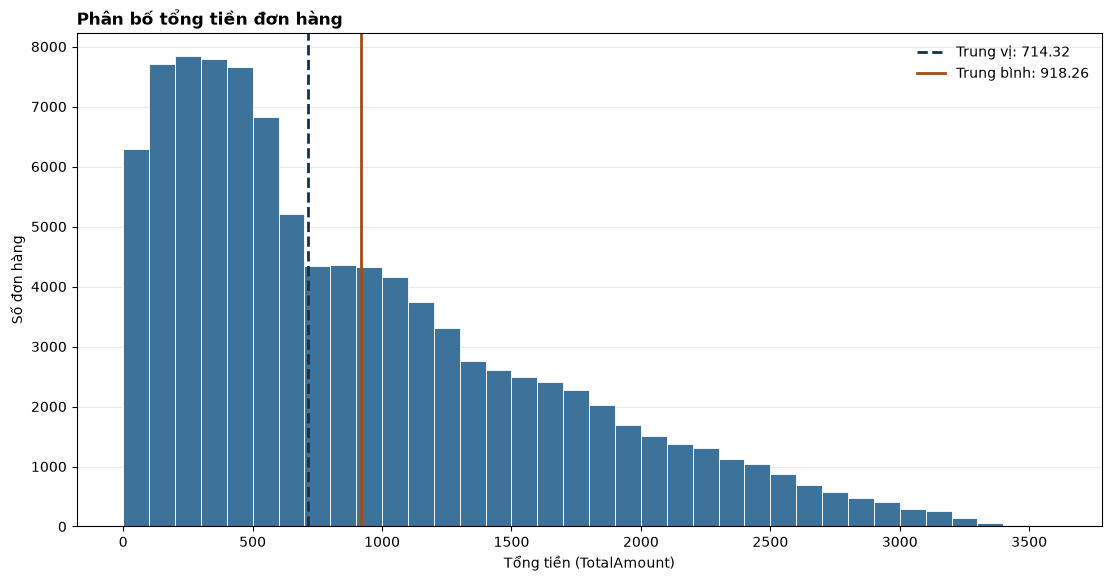

In [ ]:
import matplotlib.pyplot as plt

total = df["TotalAmount"]
median = total.median()
mean = total.mean()
bins = range(0, (int(total.max()) // 100 + 1) * 100 + 1, 100)

fig, ax = plt.subplots(figsize=(11, 5.7), layout="constrained")
ax.hist(total, bins=bins, color="#3D729A", edgecolor="white", linewidth=0.6)
ax.axvline(median, color="#173047", linestyle="--", linewidth=2,
           label=f"Trung vị: {median:.2f}")
ax.axvline(mean, color="#A64C13", linewidth=2,
           label=f"Trung bình: {mean:.2f}")

ax.set_title("Phân bố tổng tiền đơn hàng", loc="left", fontweight="bold")
ax.set_xlabel("Tổng tiền (TotalAmount)")
ax.set_ylabel("Số đơn hàng")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)

#fig.savefig("histogram_total_amount.png", dpi=220, facecolor="white")
plt.show()

In [ ]:
bang_nhat_ky = pd.DataFrame(nhat_ky)
print(bang_nhat_ky)

print(f"Tổng kết: {len(df_goc)} → {len(df)} dòng")
df.to_csv("../data/processed/Amazon_clean.csv", index=False, encoding="utf-8-sig")

                buoc                                              mo_ta  \
0         0. Ban đầu                                       Đọc file gốc   
1   1. Giá trị thiếu  Kiểm tra giá trị NaN và ngụy trang: không phát...   
2       2. Trùng lặp                         Xóa 0 dòng trùng hoàn toàn   
3  3. Định dạng ngày                    Ép datetime, bỏ 0 dòng ngày lỗi   
4   4. Giá trị vô lý  Kiểm tra các điều kiện, phát hiện 0 dòng lỗi, ...   

   so_dong_con_lai  
0           100000  
1           100000  
2           100000  
3           100000  
4           100000  
Tổng kết: 100000 → 100000 dòng
